In [1]:
import os
import sys

# necessary to make functions available
# Jupyter server should be running from src/python
sys.path.append(
    os.getcwd()
)

In [2]:
import polars as pl

import synapseclient
from synapseclient.entity import File as sceFile 

from plots_for_gsea_and_limma_results import plot_sig_up_down_feature_counts

In [3]:
# Jupyter server should be running from src/python
LIMMA_RESULTS = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_cache",
    "limma",
    "limma_results.parquet"
)

FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

LIMMA_RESULTS_SYNID = "syn78408378"

### Synapse login token/session

In [4]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.15.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.15.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [5]:
REUPLOAD_LIMMA_RESULTS = False

if REUPLOAD_LIMMA_RESULTS:
    # upload limma results to synapse
    SYN.store(sceFile(path=LIMMA_RESULTS, id=LIMMA_RESULTS_SYNID))

In [6]:
# ensure the figures directory exists
os.makedirs(FIGURE_DIR, exist_ok=True)

In [7]:
results = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)

results

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_40717/3971302718.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  results = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)



[syn78408378:limma_results.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/limma/limma_results.parquet, skipping download.


logFC,AveExpr,t,P.Value,adj.P.Val,B,Feature,OmicsType,Contrast
f64,f64,f64,f64,f64,f64,str,str,str
-0.081511,-0.11285,-0.538509,0.590664,0.709686,-6.672805,"""ACAA2-K234k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
0.287721,-0.009539,2.585739,0.010234,0.033313,-3.541081,"""ACAD9-K202k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
-0.232181,-0.117167,-1.862395,0.063618,0.143931,-5.107354,"""ACADM-K304k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
0.002934,-0.290974,0.01853,0.985229,0.994583,-6.816371,"""ACADVL-K278k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
-0.11039,-0.142724,-0.959001,0.338404,0.484085,-6.361222,"""ACADVL-K298k""","""Acetylomics""","""Black_NPM1-/FLT3-ITD-_vs_White…"
…,…,…,…,…,…,…,…,…
-0.030516,0.37894,-0.169126,0.86588,0.98462,-5.801028,"""ENSG00000266232""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"
-0.119107,0.47479,-0.772661,0.440698,0.900046,-5.540732,"""ENSG00000201863""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"
-0.049692,0.454784,-0.360979,0.718522,0.963672,-5.754391,"""ENSG00000206926""","""Transcriptomics""","""White_NPM1+/FLT3-ITD+_vs_White…"


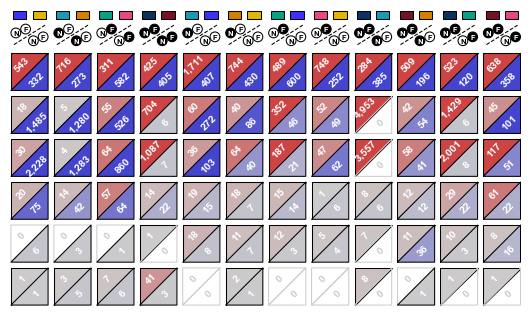

In [8]:
plot_sig_up_down_feature_counts(
    results, 
    lfc=0.5, 
    p_value=0.05,
    p_adj=False,
    figname=os.path.join(FIGURE_DIR, "limma_results_sig_up_down.png")
)

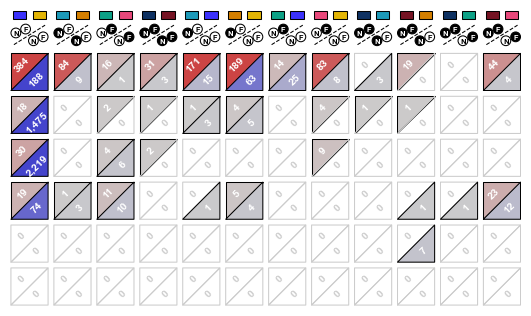

In [9]:
plot_sig_up_down_feature_counts(
    results, 
    lfc=0.5, 
    p_value=0.05,
    p_adj=True,
    figname=os.path.join(FIGURE_DIR, "limma_results_sig_up_down_padj.png")
)